In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [ ]:
df= pd.read_csv("transformed_retail_sales.csv")

In [ ]:
print(df.head())

   Row ID         Order ID  Order Date   Ship Date       Ship Mode  \
0   42433     AG-2011-2040  2011-01-01  2011-01-06  Standard Class   
1   22253    IN-2011-47883  2011-01-01  2011-01-08  Standard Class   
2   48883     HU-2011-1220  2011-01-01  2011-01-05    Second Class   
3   11731  IT-2011-3647632  2011-01-01  2011-01-05    Second Class   
4   22255    IN-2011-47883  2011-01-01  2011-01-08  Standard Class   

  Customer ID    Customer Name      Segment         City            State  \
0    TB-11280  Toby Braunhardt     Consumer  Constantine      Constantine   
1    JH-15985      Joseph Holt     Consumer  Wagga Wagga  New South Wales   
2      AT-735    Annie Thurman     Consumer     Budapest         Budapest   
3    EM-14140     Eugene Moren  Home Office    Stockholm        Stockholm   
4    JH-15985      Joseph Holt     Consumer  Wagga Wagga  New South Wales   

   ... Month_Name Quarter Profit_Margin Order_Value Customer_Segment  \
0  ...    January       1     25.995591     

In [ ]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country',
       'Market', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Shipping Cost', 'Order Priority', 'Year', 'Month', 'Month_Name',
       'Quarter', 'Profit_Margin', 'Order_Value', 'Customer_Segment',
       'Sales_Category', 'Profit_Category', 'Customer_Type',
       'Product_Performance', 'Order_Size'],
      dtype='object')


Total sales

In [ ]:
total_sales = df["Sales"].sum()
print("Total Sales:", round(total_sales, 2))

Total Sales: 12642501.91


Monthly sales analysis

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Month_Name"] = df["Order Date"].dt.month_name()
df["Month"] = df["Order Date"].dt.month
df["Year"] = df["Order Date"].dt.year

monthly_sales = (
    df.groupby(["Year", "Month", "Month_Name"])["Sales"].sum().sort_index()
)

print(monthly_sales)

Year  Month  Month_Name
2011  1      January        98898.48886
      2      February       91152.15698
      3      March         145729.36736
      4      April         116915.76418
      5      May           146747.83610
      6      June          215207.38022
      7      July          115510.41912
      8      August        207581.49122
      9      September     290214.45534
      10     October       199071.26404
      11     November      298496.53752
      12     December      333925.73460
2012  1      January       135780.72024
      2      February      100510.21698
      3      March         163076.77116
      4      April         161052.26952
      5      May           208364.89124
      6      June          256175.69842
      7      July          145236.78512
      8      August        303142.94238
      9      September     289389.16564
      10     October       252939.85020
      11     November      323512.41690
      12     December      338256.96660
2013  1      Jan

Category sales

In [ ]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Furniture          4.110874e+06
Office Supplies    3.787070e+06
Technology         4.744557e+06
Name: Sales, dtype: float64


Regional Sales

In [ ]:
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales)

Region
Africa            7.837732e+05
Canada            6.692817e+04
Caribbean         3.242809e+05
Central           2.822303e+06
Central Asia      7.528266e+05
EMEA              8.061613e+05
East              6.787812e+05
North             1.248166e+06
North Asia        8.483098e+05
Oceania           1.100185e+06
South             1.600907e+06
Southeast Asia    8.844232e+05
West              7.254578e+05
Name: Sales, dtype: float64


Product Sales

In [ ]:
product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False)

print(product_sales)

Product Name
Apple Smart Phone, Full Size                                        86935.7786
Cisco Smart Phone, Full Size                                        76441.5306
Motorola Smart Phone, Full Size                                     73156.3030
Nokia Smart Phone, Full Size                                        71904.5555
Canon imageCLASS 2200 Advanced Copier                               61599.8240
                                                                       ...    
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                      7.7000
Grip Seal Envelopes                                                     7.0720
Xerox 20                                                                6.4800
Avery 5                                                                 5.7600
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac        1.6240
Name: Sales, Length: 3788, dtype: float64


Top 10 products

In [ ]:
top_10_products = product_sales.head(10)
print(top_10_products)

Product Name
Apple Smart Phone, Full Size                                86935.7786
Cisco Smart Phone, Full Size                                76441.5306
Motorola Smart Phone, Full Size                             73156.3030
Nokia Smart Phone, Full Size                                71904.5555
Canon imageCLASS 2200 Advanced Copier                       61599.8240
Hon Executive Leather Armchair, Adjustable                  58193.4841
Office Star Executive Leather Armchair, Adjustable          50661.6840
Harbour Creations Executive Leather Armchair, Adjustable    50121.5160
Samsung Smart Phone, Cordless                               48653.4600
Nokia Smart Phone, with Caller ID                           47877.7857
Name: Sales, dtype: float64


Bottom 10 products

In [ ]:
bottom_10_products = product_sales.tail(10)
print(bottom_10_products)

Product Name
Newell 308                                                          8.400
Stockwell Gold Paper Clips                                          8.096
4009 Highlighters                                                   8.040
Xerox 1989                                                          7.968
Avery Hi-Liter Comfort Grip Fluorescent Highlighter, Yellow Ink     7.800
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                  7.700
Grip Seal Envelopes                                                 7.072
Xerox 20                                                            6.480
Avery 5                                                             5.760
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Name: Sales, dtype: float64


Profit Analysis

In [ ]:
#Total Profit
total_profit = df["Profit"].sum()
print("Total Profit:", total_profit)


Total Profit: 1467457.2912800002


In [ ]:
#Profit by Category
category_profit = df.groupby("Category")["Profit"].sum()
print("Profit by Category:", category_profit)


Profit by Category: Category
Furniture          285204.72380
Office Supplies    518473.83430
Technology         663778.73318
Name: Profit, dtype: float64


In [ ]:
#Profit by Region
region_profit = df.groupby("Region")["Profit"].sum()
print("Profit by Region:", region_profit)


Profit by Region: Region
Africa             88871.63100
Canada             17817.39000
Caribbean          34571.32104
Central           311403.98164
Central Asia      132480.18700
EMEA               43897.97100
East               91522.78000
North             194597.95252
North Asia        165578.42100
Oceania           120089.11200
South             140355.76618
Southeast Asia     17852.32900
West              108418.44890
Name: Profit, dtype: float64


In [ ]:
#Profit by Product
product_profit = (df.groupby("Product Name")["Profit"].sum())
print("Profit by Product", product_profit)

Profit by Product Product Name
"While you Were Out" Message Book, One Form per Page                                                    10.3880
#10 Gummed Flap White Envelopes, 100/Box                                                                16.7678
#10 Self-Seal White Envelopes                                                                           52.1230
#10 White Business Envelopes,4 1/8 x 9 1/2                                                             223.1408
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                115.2806
                                                                                                         ...   
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4    115.6440
iOttie HLCRIO102 Car Mount                                                                             -11.9940
iOttie XL Car Mount                                                      

Create Visualizations

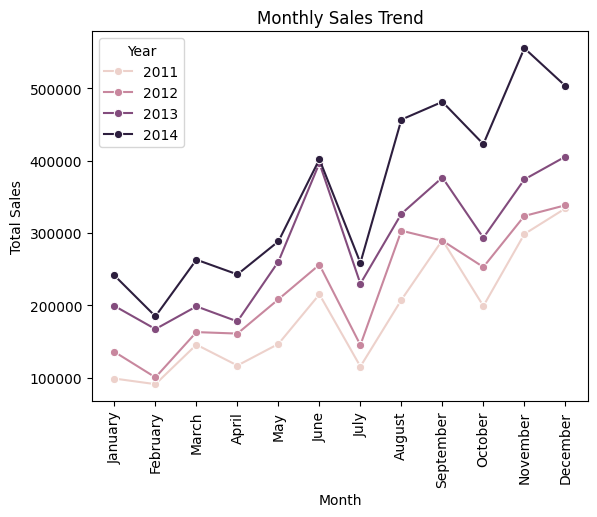

In [ ]:
#Monthly Sales Line Chart

sns.lineplot(data=monthly_sales.reset_index(), x="Month_Name", y="Sales", hue="Year", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.show()

It shows how sales change month by month across different years. It helps identify sales trends and seasonal patterns.

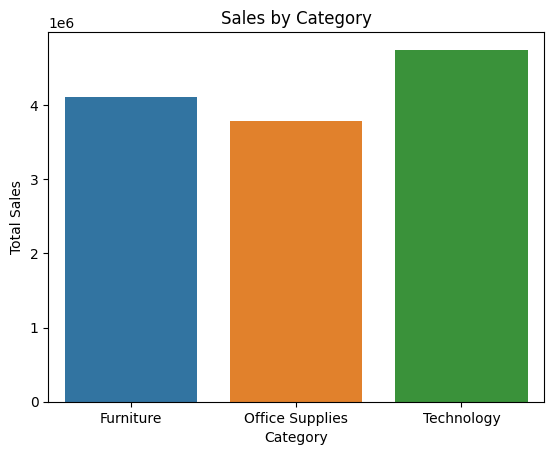

In [ ]:
#Category sales bar chart

sns.barplot(data=category_sales.reset_index(), x="Category", y="Sales" , hue="Category")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

This bar chart compares total sales across different product categories. It helps identify which category generates the highest and lowest sales.

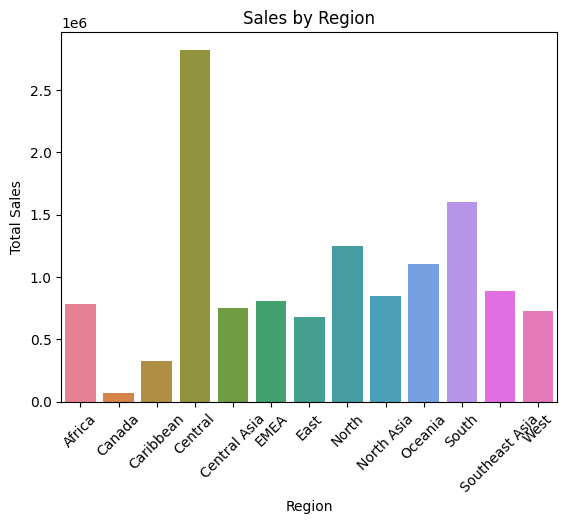

In [ ]:
#Regional Sales Bar Chart

sns.barplot(data=region_sales.reset_index(), x="Region", y="Sales", hue="Region")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

It compares sales across regions and helps identify the regions with the highest and lowest sales.

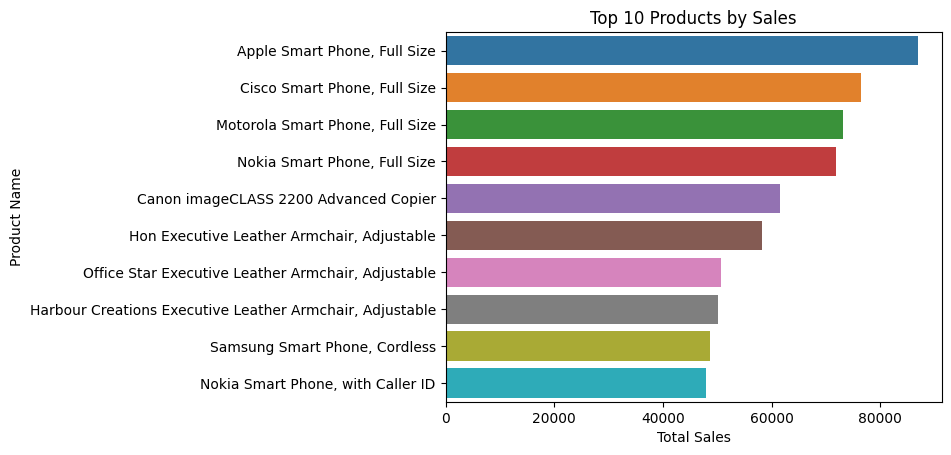

In [ ]:
#Top Products Bar Chart

sns.barplot(data=top_10_products.reset_index(), x="Sales", y="Product Name",hue= "Product Name")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.show()

It displays the ten products with the highest total sales and identifies products that contribute significantly to sales revenue.

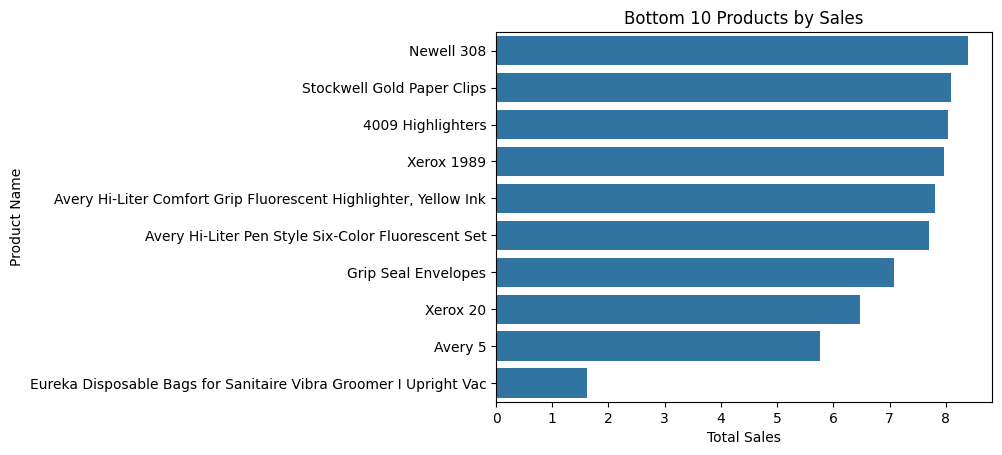

In [ ]:
#Bottom Products bar chart

sns.barplot(data=bottom_10_products.reset_index(), x="Sales", y="Product Name")

plt.title("Bottom 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.show()

It identifies the ten products with the lowest total sales and highlights products that may need further investigation.

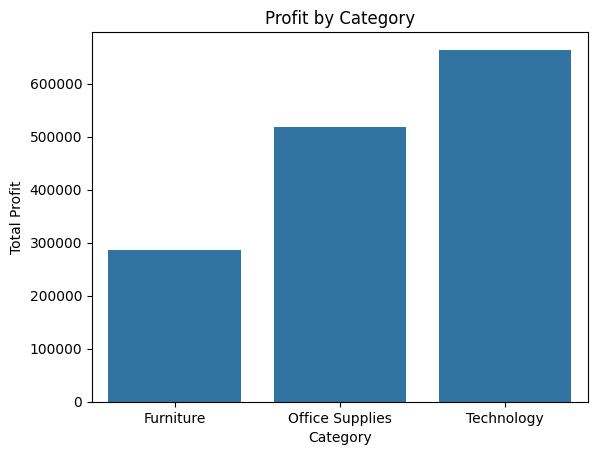

In [ ]:
#Profit by Category

sns.barplot(data=category_profit.reset_index(), x="Category", y="Profit")

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.show()

It compares total profit across product categories and helps identify which categories contribute the most profit.

In [ ]:
#Profit by Region

sns.barplot(data=region_profit, x="Region", y="Profit")

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

It compares total profit across regions and helps identify the most and least profitable regions.

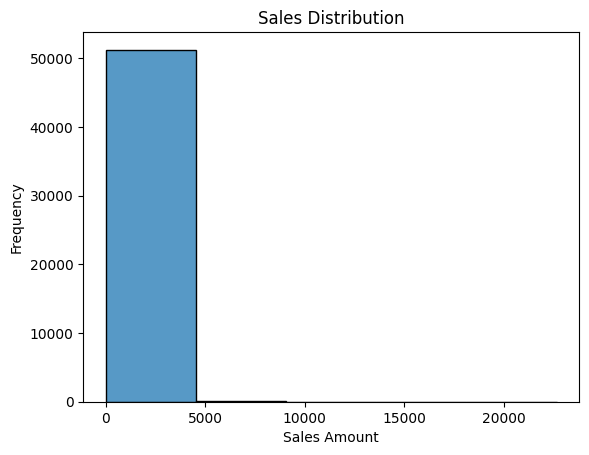

In [ ]:
#Sales Distribution Histogram

sns.histplot(data=df, x="Sales", bins=5)

plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.show()

It shows how frequently different sales amounts occur and helps us understand whether smaller or larger sales transactions are more common.